# Assignment 1: Backpropagation, 8-3-8 network
**Jessica Tambo Epoh (i6436881)**   
**Vlad Stefan (i6342904)**

## Software description and how to use it

### What this notebook does
This notebook implements a small neural network, using only
NumPy for the math (no Keras, PyTorch or other deep learning libraries).

The network has three layers:
- 8 input nodes
- 3 hidden nodes + bias
- 8 output nodes + bias

It is trained on the 8 one-hot examples (seven 0s and one 1), and the target
output is the same as the input. Because the hidden layer has only 3 nodes,
the network must learn a compressed representation of the 8 inputs.

### Requirements
- Python 3
- NumPy
- Matplotlib 

### Structure of the notebook
1. **Setup:** imports, sigmoid function, training data
2. **8-3-8 network:** one forward pass, one backpropagation
   step, to show the cost decreasing, then the full training loop
3. **Training function:** the same steps packed into `train_network()`,
   used for all experiments
4. **Experiments:** learning rate, starting weight size, cost plot
5. **Interpretation:** hidden activations and learned weights

### Implementation choices
- **Activation function:** sigmoid, g(z) = 1 / (1 + e^(−z))
- **Cost function:** least squares, J = 1/(2m) · Σ ‖h(x) − y‖²
- **Biases** are stored as separate vectors (`b1`, `b2`) instead of as an extra
  column inside the weight matrix Θ. 
- **Full-batch gradient descent:** in each epoch, all 8 examples are used and the
  weights are updated once with the average gradient.
- **No weight decay** (λ = 0).
- **Weights** start as small random numbers from a normal distribution;
  biases start at 0.
- **Convergence:** we say the network has converged at the first epoch where
  (1) for every example, the largest output is in the correct position, and
  (2) the cost J is below `tol` (default 0.01).


In [11]:
import numpy as np
import time 
import matplotlib.pyplot as plt

Forward propagation

In [3]:

def sigmoid(z):
    # sigmoid activation function
    return 1 / (1 + np.exp(-z))

# the 8 examples
X = np.eye(8)
Y = X.copy()     #target 

# random starting weights and zero biases 
rng = np.random.default_rng(0)
W1 = rng.normal(0, 0.5, (8, 3))   # input (8) -> hidden (3)
b1 = np.zeros(3)
W2 = rng.normal(0, 0.5, (3, 8))   # hidden (3) -> output (8)
b2 = np.zeros(8)

# Forward propagation 
A1 = sigmoid(X @ W1 + b1)    # hidden values
A2 = sigmoid(A1 @ W2 + b2)   # output guesses

np.set_printoptions(precision=2, suppress=True)
print("Hidden values (8 examples x 3 hidden neurons):")
print(A1)
print("\nOutput guesses (8 examples x 8 outputs):")
print(A2)
m = X.shape[0]                              
J = 0.5 * np.sum((A2 - Y) ** 2) / m
print("\nCost:", J)

Hidden values (8 examples x 3 hidden neurons):
[[0.52 0.48 0.58]
 [0.51 0.43 0.55]
 [0.66 0.62 0.41]
 [0.35 0.42 0.51]
 [0.24 0.47 0.35]
 [0.41 0.43 0.46]
 [0.55 0.63 0.48]
 [0.66 0.42 0.54]]

Output guesses (8 examples x 8 outputs):
[[0.46 0.64 0.56 0.52 0.45 0.48 0.59 0.71]
 [0.46 0.64 0.56 0.51 0.45 0.49 0.58 0.69]
 [0.5  0.62 0.52 0.49 0.43 0.49 0.55 0.69]
 [0.45 0.63 0.56 0.53 0.46 0.48 0.59 0.68]
 [0.46 0.6  0.55 0.53 0.46 0.49 0.58 0.66]
 [0.47 0.62 0.55 0.52 0.46 0.49 0.57 0.68]
 [0.47 0.64 0.55 0.51 0.43 0.49 0.58 0.71]
 [0.48 0.64 0.54 0.5  0.45 0.49 0.56 0.68]]

Cost: 1.1654551995739066


Backpropagation

In [4]:

lr = 2.0         # learning rate
# delta of the output 
d_out = (A2 - Y) * A2 * (1 - A2)

# delta of the hidden 
d_hid = (d_out @ W2.T) * A1 * (1 - A1)

# update every weight
W2 -= lr * (A1.T @ d_out) / m
b2 -= lr * d_out.mean(axis=0)
W1 -= lr * (X.T @ d_hid) / m
b1 -= lr * d_hid.mean(axis=0)

# forward propagation with the new weights and check the cost
A1 = sigmoid(X @ W1 + b1)
A2 = sigmoid(A1 @ W2 + b2)
J = 0.5 * np.sum((A2 - Y) ** 2) / m
print("J after:", J)

J after: 0.8929764552310329


Training loop

In [5]:
for epoch in range(1, 20001):
    # forward
    A1 = sigmoid(X @ W1 + b1)
    A2 = sigmoid(A1 @ W2 + b2)
    J = 0.5 * np.sum((A2 - Y) ** 2) / m

    if epoch in (1, 100, 1000, 5000, 10000, 20000):
        print(f"epoch {epoch:>5}   J = {J:.4f}")

    # backward
    d_out = (A2 - Y) * A2 * (1 - A2)
    d_hid = (d_out @ W2.T) * A1 * (1 - A1)
    W2 -= lr * (A1.T @ d_out) / m
    b2 -= lr * d_out.mean(axis=0)
    W1 -= lr * (X.T @ d_hid) / m
    b1 -= lr * d_hid.mean(axis=0)

epoch     1   J = 0.8930
epoch   100   J = 0.4218
epoch  1000   J = 0.0622
epoch  5000   J = 0.0056
epoch 10000   J = 0.0025
epoch 20000   J = 0.0012


Training Function to run multiple experiments

In [ ]:
def train_network(lr=2.0, seed=0, init_scale=0.5, max_epochs=20000, tol=0.01):
    # seed fixes the random starting weights, so results are reproducible
    # init_scale is the standard deviation of the random starting weights
    # max_epochs is the maximum number of training epochs
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, init_scale, (8, 3)); b1 = np.zeros(3)
    W2 = rng.normal(0, init_scale, (3, 8)); b2 = np.zeros(8)
    m = X.shape[0]
    history, converged_at = [], None

    for epoch in range(1, max_epochs + 1):
        # forward
        A1 = sigmoid(X @ W1 + b1)
        A2 = sigmoid(A1 @ W2 + b2)
        J = 0.5 * np.sum((A2 - Y) ** 2) / m
        history.append(J)
        # converged = first epoch where all guesses are correct and cost is below tolerance
        if converged_at is None and np.all(A2.argmax(1) == Y.argmax(1)) and J < tol:
            converged_at = epoch
        # backward
        d_out = (A2 - Y) * A2 * (1 - A2)
        d_hid = (d_out @ W2.T) * A1 * (1 - A1)
        W2 -= lr * (A1.T @ d_out) / m;  b2 -= lr * d_out.mean(axis=0)
        W1 -= lr * (X.T @ d_hid) / m;   b1 -= lr * d_hid.mean(axis=0)

    A1 = sigmoid(X @ W1 + b1)   # final hidden values
    return converged_at, history, A1

In [7]:

start = time.time()
converged_at, history, A1 = train_network(lr=2.0, seed=0)

print("Converged at epoch:", converged_at)
print("Time:", round(time.time() - start, 2), "seconds")
print("Final J:", history[-1])
print("\nHidden code (rounded):\n", np.round(A1).astype(int))

Converged at epoch: 3131
Time: 1.18 seconds
Final J: 0.0011739472915837468

Hidden code (rounded):
 [[1 0 0]
 [1 0 1]
 [1 1 0]
 [0 0 1]
 [0 1 0]
 [0 0 0]
 [0 1 1]
 [1 1 1]]


## Part 2: Learning performance

To check whether the network learns reliably,we ran two experiments. 
For every setting we trained 10 networks with different starting weights (different random seeds), each for at most 20,000 epochs. 
One epoch = all 8 examples shown once, followed by one weight update.

### Experiment 1: Learning rate
We tested learning rates from 0.1 to 100, with starting weight size 0.5.

In [8]:
learning_rates = [0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]
seeds = range(10)   # 10 different random starts for each learning rate

print("learning rate | converged (out of 10) | average epochs")
for lr in learning_rates:
    results = []
    for seed in seeds:
        converged_at, history, A1 = train_network(lr=lr, seed=seed)
        results.append(converged_at)

    # the runs that converged
    ok = [r for r in results if r is not None]
    avg = round(np.mean(ok)) if ok else "-"
    print(f"{lr:>13} | {len(ok):>21} | {avg}")

learning rate | converged (out of 10) | average epochs
          0.1 |                     0 | -
          0.5 |                    10 | 13319
            1 |                    10 | 6659
            2 |                    10 | 3330
            5 |                    10 | 1338
           10 |                    10 | 669
           20 |                    10 | 376
           50 |                    10 | 4121
          100 |                     0 | -


- 0.1: too small, the steps are so small that the network does not reach
  the convergence threshold within 20,000 epochs.
- 0.5 to 20: the network converges for every seed. Doubling the learning
  rate roughly halves the number of epochs needed.
- 50: too large, the network still converges, but it is much slower again,
  because the large steps overshoot the minimum.                                                        
- 100: the network never converges.
So with any learning rate between 0.5 and 50 it learned the task for all 10 random starts.
One training run of 20,000 epochs takes about 1 second.  
With learning rate 2 and seed 0, the network converged after 3131 epochs.



### Experiment 2: Size of the starting weights
The starting weights are drawn from a normal distribution with standard deviation
`init_scale`. We tested values from 0 (all weights start at zero) to 5,
with learning rate 5.

In [9]:
init_scales = [0, 0.01, 0.1, 0.5, 1, 2, 5]

print("starting weight size | converged (out of 10) | average epochs")
for scale in init_scales:
    results = []
    for seed in range(10):
        converged_at, history, A1 = train_network(lr=5, seed=seed, init_scale=scale)
        results.append(converged_at)

    ok = [r for r in results if r is not None]
    avg = round(np.mean(ok)) if ok else "-"
    print(f"{scale:>20} | {len(ok):>21} | {avg}")

starting weight size | converged (out of 10) | average epochs
                   0 |                    10 | 14580
                0.01 |                    10 | 1816
                 0.1 |                    10 | 1570
                 0.5 |                    10 | 1338
                   1 |                    10 | 1373
                   2 |                    10 | 1792
                   5 |                     5 | 7917


- 0.01–2: always converges, fastest around 0.5.
- 5: only half of the networks converged, and slowly.
  With large weights the sigmoid neurons start close to 0 or 1, where their
  slope a(1 − a) is almost zero. The gradients are then tiny, so the neurons
  are almost frozen and learn very slowly.
- All weights 0 :if every weight starts at the same value, all three
  hidden units compute exactly the same thing. They then receive exactly the same
  error signal during backpropagation, so they get the same updates and stay
  identical. In theory, the network then behaves as if it had only one hidden unit,
  and one unit is not enough to tell 8 inputs apart. This is called the
  symmetry problem, and it is the reason why weights are normally initialised
  randomly ("symmetry breaking").

  In our run, the network still converged, but it needed 14,580 epochs, about
  10 times more than with small random weights (1,338 epochs for size 0.5).
  The hidden activations explain why. Hidden units 1 and 2 have exactly
  the same value for every input, so they never separated. Hidden unit 3, however,
  became different. Since nothing in the code is random when all weights are 0,
  this difference most likely comes from tiny rounding errors in the computer's
  calculations, which broke the symmetry by accident. Backpropagation then slowly
  made this tiny difference bigger.

  As a result, the network had effectively only two different hidden units instead
  of three. It still managed to separate the 8 inputs, but only by using in-between
  values, such as 0.26 and 0.72 instead of a clean on/off code, which is harder
  and therefore much slower to learn.

  The seed has no effect here: with a starting weight size of 0, every weight is
  exactly 0, no matter the seed. All 10 runs were therefore the same network,
  which is why all 10 gave the same result


In [10]:
converged_at, history, A1 = train_network(lr=5, seed=0, init_scale=0)
print("Hidden values when all weights start at 0:\n", A1)

Hidden values when all weights start at 0:
 [[0.   0.   0.6 ]
 [0.26 0.26 0.  ]
 [0.03 0.03 0.24]
 [0.18 0.18 0.93]
 [1.   1.   0.27]
 [0.72 0.72 0.  ]
 [0.64 0.64 1.  ]
 [1.   1.   0.72]]


The hidden activations show that the symmetry was only partly
broken: hidden units 1 and 2 stayed exactly identical. The network solved the
task with effectively only two different hidden units, using intermediate
values, such as 0.26 and 0.72, instead of a binary-like code. This explains
the slow convergence.

**Conclusion:** the weights must start small and random, to break the
symmetry between hidden units without saturating the sigmoid.

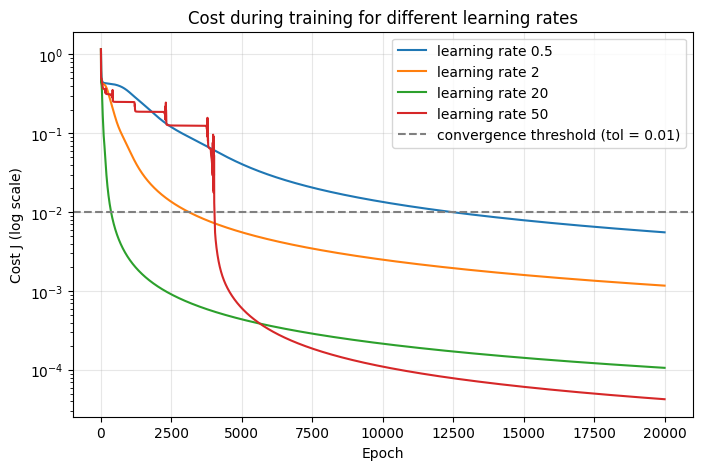

In [12]:
plt.figure(figsize=(8, 5))
for lr in [0.5, 2, 20, 50]:
    converged_at, history, A1 = train_network(lr=lr, seed=0)
    plt.plot(history, label=f"learning rate {lr}")

plt.yscale("log")   # log scale: makes small costs visible (explained below)
plt.axhline(0.01, color="gray", linestyle="--", label="convergence threshold (tol = 0.01)")
plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Cost during training for different learning rates")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Cost during training
The plot shows the cost J for four learning rates (seed 0). The y-axis uses a
log scale so that small costs remain visible. The dashed line is the
convergence threshold (J = 0.01).

- lr = 20 drops fastest and crosses the threshold almost immediately.
- lr = 2 decreases steadily and crosses it at around 3,000 epochs.
- lr = 0.5  is slow and needs about 12,500 epochs.
- lr = 50 shows flat plateaus with sudden spikes: the network is stuck,
  overshoots, and gets stuck again. After about 4,000 epochs it suddenly finds
  a good direction and the cost drops quickly.

## Part 3: Interpretation of the learned weights

We now look inside the network trained: learning rate 2, seed 0.   
First we look at the activations of the 3 hidden
units for each of the 8 inputs, then at the weights themselves.

In [13]:
A1 = sigmoid(X @ W1 + b1)   # recompute hidden values of the trained network

print("Hidden values:\n", A1)
print("\nRounded hidden code:")
for i in range(8):
    print(f"input {i}  ->  {np.round(A1[i]).astype(int)}")

Hidden values:
 [[0.99 0.23 0.02]
 [0.9  0.01 0.96]
 [0.78 0.99 0.01]
 [0.01 0.22 0.99]
 [0.01 0.59 0.01]
 [0.2  0.   0.15]
 [0.02 0.99 0.81]
 [0.99 0.98 0.99]]

Rounded hidden code:
input 0  ->  [1 0 0]
input 1  ->  [1 0 1]
input 2  ->  [1 1 0]
input 3  ->  [0 0 1]
input 4  ->  [0 1 0]
input 5  ->  [0 0 0]
input 6  ->  [0 1 1]
input 7  ->  [1 1 1]


### The hidden layer learned a binary-like code

Most hidden activations are close to 0 or 1, so each hidden unit behaves
almost like an on/off switch. With 3 switches there are exactly
2 × 2 × 2 = 8 possible patterns, and the network uses every pattern exactly once.
Nobody told the network to do this: it discovered a 3-bit code by itself.

Why every input needs a different code: the output layer only receives the
3 hidden values, it never sees the original input. If two inputs produced the
same hidden pattern, the output layer would receive exactly the same information
for both and could not know which output to switch on. To reproduce all 8 inputs
correctly, every input must therefore get its own pattern. With only 3 hidden
units, this forces the network to use all 8 combinations.

The code is not ordinary binary counting: input 0 gets `1 0 0`, not `0 0 0`.
Which input gets which pattern is arbitrary, and depends on the random starting
weights.

The code is binary-like, but not perfectly binary: some values are clearly
not 0 or 1. For example, input 4 has a middle value of 0.59, and input 5 has
0.20 and 0.15. The network does not need perfect 0s and 1s: the codes only need
to be different enough for the output layer to tell them apart. Our all-zero
experiment showed the extreme case of this, where the network used
in-between values such as 0.26 and 0.72 instead of an on/off code.

In [14]:
np.set_printoptions(precision=1, suppress=True)
print("W1 (input -> hidden), one row per input:\n", W1)
print("\nW2 (hidden -> output), one column per output:\n", W2)
np.set_printoptions(precision=2, suppress=True)   

W1 (input -> hidden), one row per input:
 [[ 5.  -1.4 -3.9]
 [ 2.5 -5.   3.3]
 [ 1.5  4.8 -4.5]
 [-4.7 -1.5  4.4]
 [-4.9  0.1 -4.9]
 [-1.1 -6.  -1.6]
 [-3.9  5.   1.5]
 [ 5.   3.8  5.1]]

W2 (hidden -> output), one column per output:
 [[  9.9   6.1   3.7 -10.1 -12.   -5.4  -8.4   6.2]
 [ -6.9  -9.6  10.4  -7.4   4.8 -15.1  10.4   6.3]
 [ -8.9   6.2  -8.4   8.6 -11.4  -5.8   3.8   5.9]]


### The weights: W1 is a code book, W2 is a decoder

**W1 (input → hidden).** Each input contains a single 1 and seven 0s, so input i
only "activates" row i of W1: all other rows are multiplied by 0. Row i of W1
therefore directly determines the hidden code of input i. A positive weight
switches the hidden unit on, a negative weight switches it off:

So W1 works stores one 3-bit code per input.
The size of the weight also matters. Input 4 has a middle weight of only 0.1,
which is why its middle hidden value (0.59) is the least clear of all.

**W2 (hidden → output).** Each column of W2 belongs to one output unit.
The signs of each column match the code of the input that output should
reproduce:

Each output unit has learned a template of its own code: positive weights
where its code has a 1, negative weights where its code has a 0. It only gets a
large positive input when the hidden pattern matches its template, so it lights
up for its own input and stays off for all others.

Together, the network works as an encoder–decoder: W1 compresses the 8 inputs
into a 3-dimensional code, and W2 decodes that code back into the original input.
This is an example of what the lecture calls a latent representation: a hidden,
compressed description of the data that the network discovers by itself.

## Conclusion

We implemented an 8-3-8 neural network with backpropagation from scratch, using
only NumPy. The network learned to reproduce all 8 one-hot inputs.

Learning is reliable: for every learning rate between 0.5 and 50, all 10
random starts converged. A learning rate around 20 was fastest (376 epochs on
average), while values that were too small (0.1) or too large (100) did not
converge. The starting weights must be small and random: too large weights
saturate the sigmoid and slow learning down, and all-zero weights create a
symmetry problem between the hidden units.

Looking inside the trained network, the 3 hidden units learned a binary-like
code, using all 8 possible on/off patterns. W1 acts as a code book that assigns
a code to each input, and W2 acts as a decoder that turns the code back into the
original input. The network discovered this compressed representation entirely
by itself.